# Clasificación de tipo de rostro (MTCNN + FaceNet)

## 0. Configuración

In [ ]:
!pip install -q facenet-pytorch --no-deps
!pip install -q wandb dlib

In [ ]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2, dlib, wandb
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from facenet_pytorch import MTCNN, InceptionResnetV1
from google.colab import drive

drive.mount('/content/drive')
device = 'cuda' if torch.cuda.is_available() else 'cpu'

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

# ---- Datos ----------------------------------------------------------------
CLASES = ['Redondo', 'Rectangular', 'Ovalado', 'Cuadrado']
NUM_CLASES = len(CLASES)
EXT = ('.jpg', '.jpeg', '.png')
BASE = '/content/drive/MyDrive/IA2/Dataset - Rostros Masculinos'
RUTAS = dict(
    dataset='/content/drive/MyDrive/Octavo/Inteligencia Artificial 2/Proyecto/Train',  # imágenes originales
    recortes=f'{BASE}/dataset_rostros_mtcnn',          # salida de MTCNN (color)
    preprocesado=f'{BASE}/dataset_rostros_preprocesado',  # salida del preprocesamiento del paper
    test_dataset='/content/drive/MyDrive/Octavo/Inteligencia Artificial 2/Proyecto/Test',  # imágenes originales de test
    test_recortes=f'{BASE}/dataset_rostros_mtcnn_test',          # salida de MTCNN (test, color)
    test_preprocesado=f'{BASE}/dataset_rostros_preprocesado_test',  # preprocesamiento del paper (test)
    checkpoints='/content/drive/MyDrive/IA2/checkpoints',
)
os.makedirs(RUTAS['checkpoints'], exist_ok=True)
IMG_SIZE, EMB_DIM = 160, 512

# ---- Weights & Biases -----------------------------------------------------
USE_WANDB = True
WANDB_PROYECTO = 'face-shape-haircut'
if USE_WANDB:
    wandb.login()   # pega tu API key cuando la pida (https://wandb.ai/authorize)

# ---- Hiperparámetros base (= configuración original, sin regularización) ---
BASE_CFG = dict(
    input='color',            # 'color' (recorte MTCNN) o 'preprocesado' (contorno+umbral del paper)
    epocas=40,
    batch_size=32,
    lr_backbone=1e-4, lr_head=1e-4,
    weight_decay=0.0,
    label_smoothing=0.0,
    lam=0.01,                 # peso de Center Loss (0 = desactivado)
    # --- técnicas a probar ---
    aug='none',               # 'none' | 'basica' | 'fuerte'
    dropout=0.0,              # Dropout antes de la capa final
    bn_head=False,            # BatchNorm1d en la cabeza
    usar_scheduler=False,     # ReduceLROnPlateau
    lr_factor=0.5, lr_patience=3,
    early_stopping=False,
    es_patience=8,
    monitor='val_loss',       # métrica de ModelCheckpoint / EarlyStopping / scheduler: 'val_loss' | 'val_acc'
)

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: hecfrant (hecfrant-universidad-industrial-de-santander) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## 1. Preparación de datos (se ejecuta una sola vez)
Detección con **MTCNN** → 68 landmarks con **dlib** → preprocesamiento del paper (resta del contorno, CLAHE, nitidez, umbral).
Las imágenes ya generadas en Drive se omiten, así que volver a ejecutar esta sección es barato.

In [ ]:
!wget -nc -q http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
!bzip2 -dk shape_predictor_68_face_landmarks.dat.bz2 2>/dev/null || true

In [ ]:
mtcnn = MTCNN(keep_all=False, device=device)
predictor = dlib.shape_predictor('shape_predictor_68_face_landmarks.dat')
MARGEN = 0.1

def recortar_rostro(img):
    """Devuelve el rostro recortado (160x160) o None si MTCNN no detecta nada."""
    boxes, probs = mtcnn.detect(img)
    if boxes is None:
        return None
    x1, y1, x2, y2 = boxes[probs.argmax()]
    w, h = x2 - x1, y2 - y1
    caja = (int(x1 - MARGEN * w), int(y1 - MARGEN * h), int(x2 + MARGEN * w), int(y2 + MARGEN * h))
    return img.crop(caja).resize((IMG_SIZE, IMG_SIZE))

def obtener_landmarks(img_pil):
    arr = np.array(img_pil)
    rect = dlib.rectangle(0, 0, arr.shape[1], arr.shape[0])   # la imagen ya es el rostro
    return np.array([(p.x, p.y) for p in predictor(arr, rect).parts()])

def preprocesar(img_pil, pts):
    """Pipeline del paper. Devuelve todas las etapas; la última es la imagen final."""
    gris = cv2.cvtColor(np.array(img_pil), cv2.COLOR_RGB2GRAY)
    contorno = np.zeros_like(gris)
    cv2.polylines(contorno, [pts[0:17].astype(np.int32)], False, 255, 2)   # mandíbula (0-16)
    resta = cv2.subtract(gris, contorno)
    contraste = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(resta)
    nitida = cv2.filter2D(contraste, -1, np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]))
    final = np.where(nitida > 30, 30, 255).astype(np.uint8)
    return gris, resta, contraste, nitida, final

def generar_datasets(origen='dataset', recortes='recortes', preprocesado='preprocesado'):
    fallos = {c: [] for c in CLASES}
    for c in CLASES:
        os.makedirs(f"{RUTAS[recortes]}/{c}", exist_ok=True)
        os.makedirs(f"{RUTAS[preprocesado]}/{c}", exist_ok=True)
        for nombre in tqdm(sorted(os.listdir(f"{RUTAS[origen]}/{c}")), desc=c):
            if not nombre.lower().endswith(EXT):
                continue
            ruta_rec = f"{RUTAS[recortes]}/{c}/{nombre}"
            ruta_pre = f"{RUTAS[preprocesado]}/{c}/{os.path.splitext(nombre)[0]}.png"
            try:
                if not os.path.exists(ruta_rec):                       # 1) MTCNN
                    cara = recortar_rostro(Image.open(f"{RUTAS[origen]}/{c}/{nombre}").convert('RGB'))
                    if cara is None:
                        fallos[c].append(nombre); continue
                    cara.save(ruta_rec)
                if not os.path.exists(ruta_pre):                       # 2) landmarks + preprocesamiento
                    cara = Image.open(ruta_rec).convert('RGB')
                    Image.fromarray(preprocesar(cara, obtener_landmarks(cara))[-1]).save(ruta_pre)
            except Exception:
                fallos[c].append(nombre)
    for c in CLASES:
        print(f'{c:12s} fallos: {len(fallos[c])}')

print('--- Train ---'); generar_datasets()
print('--- Test ---');  generar_datasets('test_dataset', 'test_recortes', 'test_preprocesado')

--- Train ---


Redondo:   0%|          | 0/323 [00:00<?, ?it/s]

Rectangular:   0%|          | 0/317 [00:00<?, ?it/s]

Ovalado:   0%|          | 0/320 [00:00<?, ?it/s]

Cuadrado:   0%|          | 0/323 [00:00<?, ?it/s]

Redondo      fallos: 0
Rectangular  fallos: 1
Ovalado      fallos: 0
Cuadrado     fallos: 0
--- Test ---


Redondo:   0%|          | 0/83 [00:00<?, ?it/s]

Rectangular:   0%|          | 0/83 [00:00<?, ?it/s]

Ovalado:   0%|          | 0/81 [00:00<?, ?it/s]

Cuadrado:   0%|          | 0/80 [00:00<?, ?it/s]

Redondo      fallos: 0
Rectangular  fallos: 0
Ovalado      fallos: 0
Cuadrado     fallos: 0


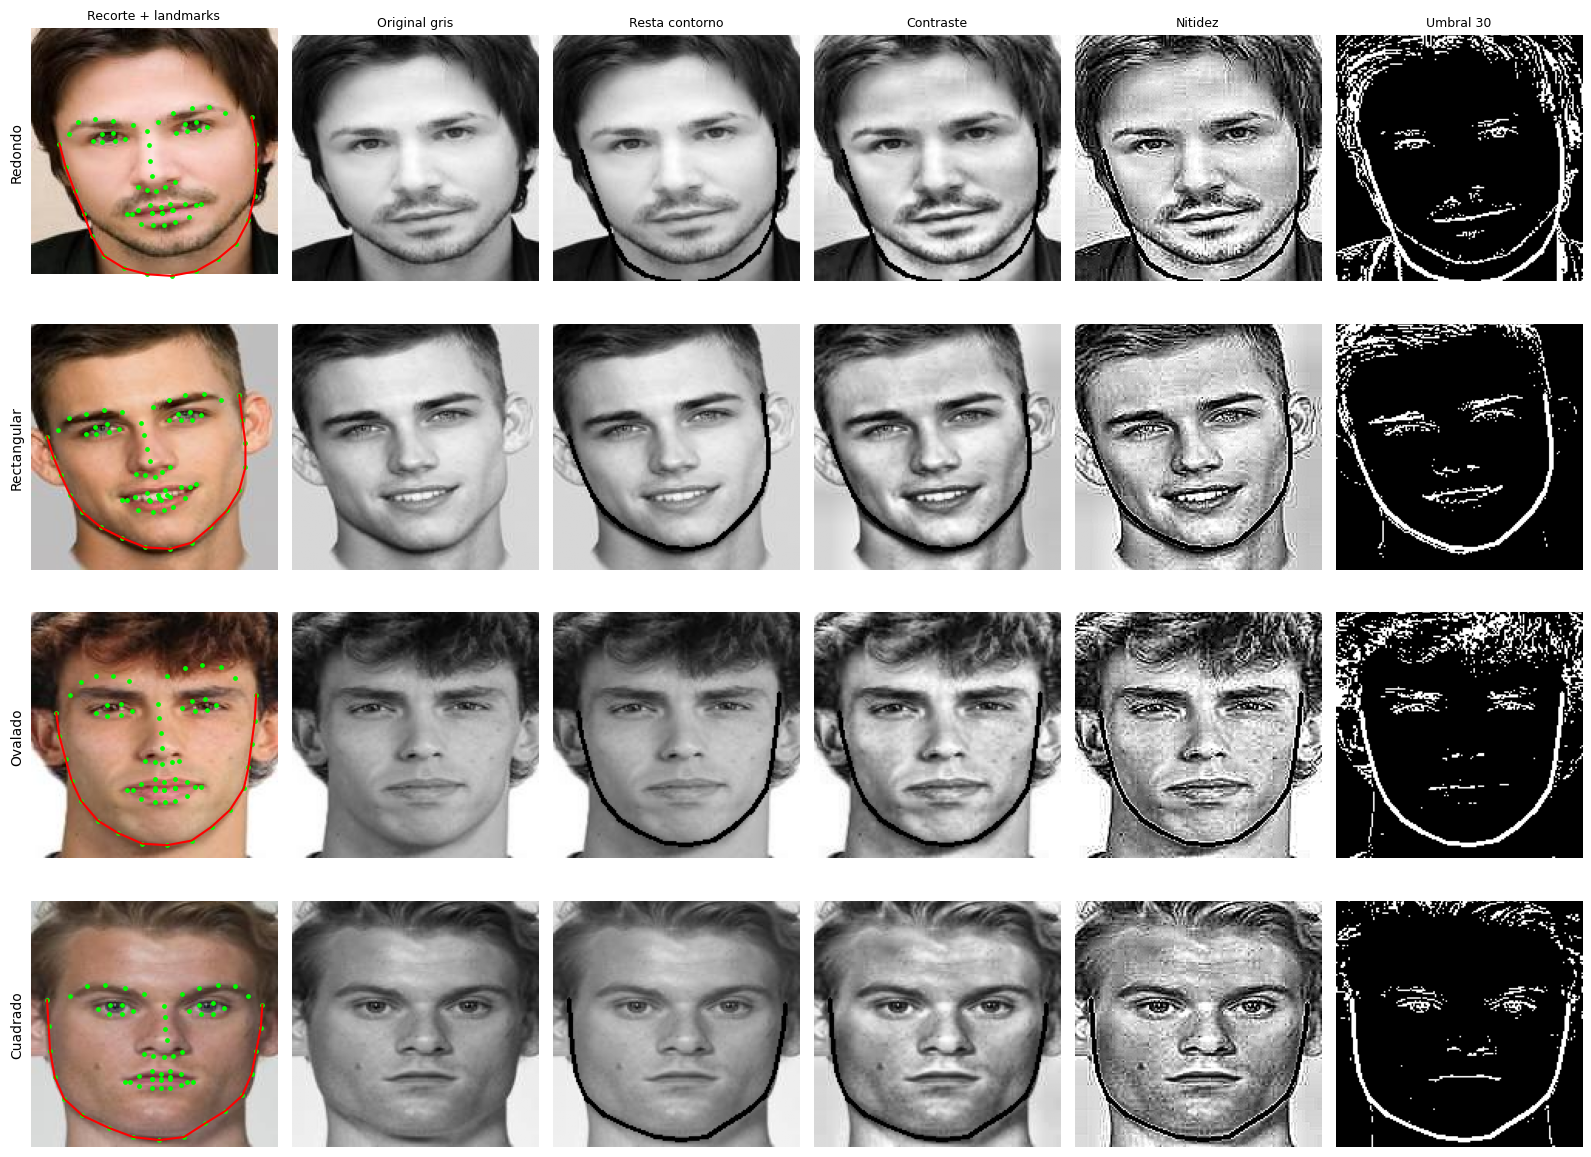

In [ ]:
# Verificación visual (opcional): landmarks y etapas del preprocesamiento
fig, axes = plt.subplots(len(CLASES), 6, figsize=(16, 3 * len(CLASES)))
titulos = ['Recorte + landmarks', 'Original gris', 'Resta contorno', 'Contraste', 'Nitidez', 'Umbral 30']
for i, c in enumerate(CLASES):
    carpeta = f"{RUTAS['recortes']}/{c}"
    img = Image.open(f"{carpeta}/{sorted(os.listdir(carpeta))[0]}").convert('RGB')
    pts = obtener_landmarks(img)
    axes[i, 0].imshow(img); axes[i, 0].scatter(pts[:, 0], pts[:, 1], s=6, c='lime')
    axes[i, 0].plot(pts[:17, 0], pts[:17, 1], c='red')
    for j, etapa in enumerate(preprocesar(img, pts), start=1):
        axes[i, j].imshow(etapa, cmap='gray')
    for j in range(6):
        axes[i, j].axis('off')
        if i == 0: axes[i, j].set_title(titulos[j], fontsize=9)
    axes[i, 0].text(-5, 80, c, rotation=90, va='center', ha='right')
plt.tight_layout(); plt.show()

## 2. Datos: split y *data augmentation*
Split estratificado **80 / 20** (train / val) con semilla fija, a partir de la carpeta `Train`. El test usa la carpeta `test` existente (no se saca de train). Con pocas imágenes en val la métrica tiene ruido: no sobreinterpretes diferencias pequeñas entre experimentos.

Niveles de augmentation (`cfg['aug']`):
- `none`: solo resize + normalización.
- `basica`: flip horizontal + rotación ±10°.
- `fuerte`: lo anterior + recorte/zoom suave (manteniendo la proporción, para no deformar la forma del rostro), `ColorJitter` (solo en modo `color`) y `RandomErasing` (simula oclusiones por cabello/accesorios).

No se usan flip vertical ni deformaciones de aspecto: cambiarían la propia etiqueta (la forma del rostro).

In [ ]:
NORM = transforms.Normalize([0.5] * 3, [0.5] * 3)

def crear_transforms(cfg):
    res = transforms.Resize((IMG_SIZE, IMG_SIZE))
    if cfg['aug'] == 'none':
        extra = []
    elif cfg['aug'] == 'basica':
        extra = [transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)]
    elif cfg['aug'] == 'fuerte':
        extra = [transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
                 transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05))]
        if cfg['input'] == 'color':
            extra.append(transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2))
    else:
        raise ValueError(cfg['aug'])
    train_tf = transforms.Compose([res, *extra, transforms.ToTensor()] +
                                  ([transforms.RandomErasing(p=0.25, scale=(0.02, 0.1))] if cfg['aug'] == 'fuerte' else []) +
                                  [NORM])
    test_tf = transforms.Compose([res, transforms.ToTensor(), NORM])
    return train_tf, test_tf

class RostrosDataset(Dataset):
    def __init__(self, rutas, etiquetas, tf):
        self.rutas, self.etiquetas, self.tf = rutas, etiquetas, tf
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, i):
        return self.tf(Image.open(self.rutas[i]).convert('RGB')), self.etiquetas[i]

_splits = {}
def _listar(raiz):
    rutas, y = [], []
    for idx, c in enumerate(CLASES):
        for n in sorted(os.listdir(f'{raiz}/{c}')):
            if n.lower().endswith(EXT):
                rutas.append(f'{raiz}/{c}/{n}'); y.append(idx)
    return rutas, y

def obtener_split(input_tipo):
    if input_tipo not in _splits:
        raiz = RUTAS['recortes'] if input_tipo == 'color' else RUTAS['preprocesado']
        raiz_test = RUTAS['test_recortes'] if input_tipo == 'color' else RUTAS['test_preprocesado']
        rutas, y = _listar(raiz)
        X_tr, X_va, y_tr, y_va = train_test_split(rutas, y, test_size=0.20, stratify=y, random_state=SEED)  # solo train / val
        X_te, y_te = _listar(raiz_test)                                                                      # test: carpeta existente
        _splits[input_tipo] = (X_tr, y_tr, X_va, y_va, X_te, y_te)
    return _splits[input_tipo]

def crear_datos(cfg):
    X_tr, y_tr, X_va, y_va, X_te, y_te = obtener_split(cfg['input'])
    train_tf, test_tf = crear_transforms(cfg)
    kw = dict(batch_size=cfg['batch_size'], num_workers=2, pin_memory=True)
    return dict(
        train=DataLoader(RostrosDataset(X_tr, y_tr, train_tf), shuffle=True, drop_last=True, **kw),  # drop_last: BatchNorm necesita batch>1
        val=DataLoader(RostrosDataset(X_va, y_va, test_tf), **kw),
        test=DataLoader(RostrosDataset(X_te, y_te, test_tf), **kw),
        y_train=y_tr)

X_tr, y_tr, X_va, y_va, X_te, y_te = obtener_split(BASE_CFG['input'])
print(f'Train: {len(X_tr)} | Val: {len(X_va)} | Test: {len(X_te)}')
print('Train por clase:', {CLASES[i]: y_tr.count(i) for i in range(NUM_CLASES)})

Train: 1024 | Val: 256 | Test: 327
Train por clase: {'Redondo': 258, 'Rectangular': 253, 'Ovalado': 255, 'Cuadrado': 258}


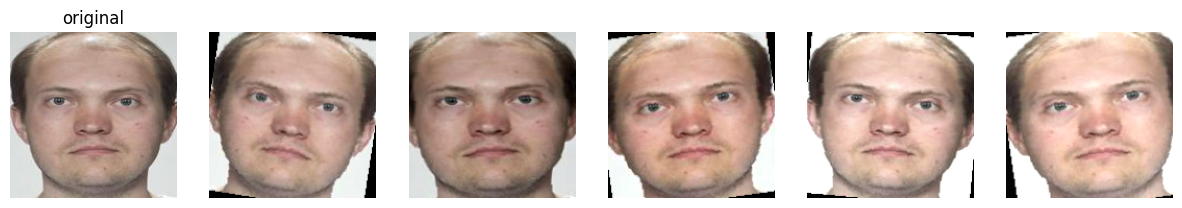

In [ ]:
# Vista previa de augmentation (opcional)
vista = dict(BASE_CFG, aug='fuerte')
tf_vista, _ = crear_transforms(vista)
img0 = Image.open(X_tr[0]).convert('RGB')
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img0); axes[0].set_title('original')
for a in axes[1:]:
    a.imshow((tf_vista(img0) * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1))
for a in axes: a.axis('off')
plt.show()

## 3. Modelo
- **Backbone:** `InceptionResnetV1` preentrenado en VGGFace2 (embedding de 512 dimensiones). Ya trae BatchNorm interna.
- **Cabeza:** `[BatchNorm1d] → [Dropout] → Linear(512, 4)`; BN y Dropout se activan por configuración.
- **Pérdida:** CrossEntropy (con pesos por clase y *label smoothing* opcional) + `λ · CenterLoss` sobre el embedding.
- **Optimizador:** AdamW con *learning rate* distinto para backbone (bajo, para no destruir lo preentrenado) y cabeza (mayor).

In [ ]:
class FaceNetClasificador(nn.Module):
    def __init__(self, dropout=0.0, bn_head=False):
        super().__init__()
        self.backbone = InceptionResnetV1(pretrained='vggface2')
        capas = []
        if bn_head: capas.append(nn.BatchNorm1d(EMB_DIM))
        if dropout > 0: capas.append(nn.Dropout(dropout))
        capas.append(nn.Linear(EMB_DIM, NUM_CLASES))
        self.head = nn.Sequential(*capas)
    def forward(self, x):
        emb = self.backbone(x)
        return emb, self.head(emb)

class CenterLoss(nn.Module):
    def __init__(self, num_clases, dim):
        super().__init__()
        self.centros = nn.Parameter(torch.randn(num_clases, dim))
    def forward(self, emb, etiquetas):
        return ((emb - self.centros[etiquetas]) ** 2).sum(dim=1).mean() / 2

## 4. Entrenamiento
Callbacks implementados a mano (equivalentes a los de Keras):
- **ModelCheckpoint:** guarda en Drive el modelo con mejor métrica de validación.
- **EarlyStopping:** detiene el entrenamiento si la validación no mejora en `es_patience` épocas.
- **ReduceLROnPlateau:** reduce el LR del optimizador por `lr_factor` si la validación se estanca `lr_patience` épocas.
- **W&B:** registra pérdidas, accuracies y LR por época, más un resumen por corrida.

In [ ]:
class ModelCheckpoint:
    def __init__(self, ruta, monitor='val_loss'):
        self.ruta, self.monitor = ruta, monitor
        self.signo = 1 if monitor == 'val_loss' else -1      # minimizar val_loss / maximizar val_acc
        self.mejor, self.mejor_epoca = float('inf'), 0
    def __call__(self, metricas, modelo, epoca):
        valor = self.signo * metricas[self.monitor]
        if valor < self.mejor:
            self.mejor, self.mejor_epoca = valor, epoca
            torch.save(modelo.state_dict(), self.ruta)
            return True
        return False

class EarlyStopping:
    def __init__(self, patience, monitor='val_loss', min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.signo = 1 if monitor == 'val_loss' else -1
        self.mejor, self.sin_mejora = float('inf'), 0
    def __call__(self, valor):
        valor = self.signo * valor
        if valor < self.mejor - self.min_delta:
            self.mejor, self.sin_mejora = valor, 0
        else:
            self.sin_mejora += 1
        return self.sin_mejora >= self.patience

@torch.no_grad()
def evaluar(modelo, loader):
    modelo.eval()
    loss, ok, n, preds, reales = 0.0, 0, 0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        _, logits = modelo(x)
        loss += F.cross_entropy(logits, y, reduction='sum').item()   # CE simple: comparable entre experimentos
        p = logits.argmax(1)
        ok += (p == y).sum().item(); n += y.size(0)
        preds += p.cpu().tolist(); reales += y.cpu().tolist()
    return loss / n, ok / n, preds, reales

def diagnostico(train_acc, val_acc):
    gap = train_acc - val_acc
    if train_acc < 0.80:
        return f'posible UNDERFITTING (train {train_acc:.2f}): el modelo no aprende ni el train'
    if gap > 0.10:
        return f'OVERFITTING (brecha train-val = {gap:.2f})'
    return f'ajuste razonable (brecha train-val = {gap:.2f})'

def entrenar(nombre, overrides=None, grupo='ablacion'):
    cfg = {**BASE_CFG, **(overrides or {})}
    set_seed()
    datos = crear_datos(cfg)

    model = FaceNetClasificador(cfg['dropout'], cfg['bn_head']).to(device)
    center = CenterLoss(NUM_CLASES, EMB_DIM).to(device)
    conteo = torch.bincount(torch.tensor(datos['y_train']), minlength=NUM_CLASES).float()
    ce = nn.CrossEntropyLoss(weight=(conteo.sum() / (NUM_CLASES * conteo)).to(device),
                             label_smoothing=cfg['label_smoothing'])
    opt = torch.optim.AdamW([{'params': model.backbone.parameters(), 'lr': cfg['lr_backbone']},
                             {'params': model.head.parameters(), 'lr': cfg['lr_head']}],
                            weight_decay=cfg['weight_decay'])
    opt_c = torch.optim.SGD(center.parameters(), lr=0.5)
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(
                opt, mode='min' if cfg['monitor'] == 'val_loss' else 'max',
                factor=cfg['lr_factor'], patience=cfg['lr_patience'])
             if cfg['usar_scheduler'] else None)

    ruta_ckpt = f"{RUTAS['checkpoints']}/{nombre}.pt"
    ckpt = ModelCheckpoint(ruta_ckpt, cfg['monitor'])
    stopper = EarlyStopping(cfg['es_patience'], cfg['monitor']) if cfg['early_stopping'] else None
    run = wandb.init(project=WANDB_PROYECTO, name=nombre, group=grupo, config=cfg, reinit=True) if USE_WANDB else None

    hist, lam = [], cfg['lam']
    for ep in range(1, cfg['epocas'] + 1):
        model.train()
        tl, ok, n = 0.0, 0, 0
        for x, y in datos['train']:
            x, y = x.to(device), y.to(device)
            emb, logits = model(x)
            loss = ce(logits, y)
            if lam > 0:
                loss = loss + lam * center(emb, y)
            opt.zero_grad(); opt_c.zero_grad()
            loss.backward()
            if lam > 0:
                for p in center.parameters():
                    p.grad.mul_(1.0 / lam)     # los centros se actualizan sin que λ los frene
            opt.step()
            if lam > 0:
                opt_c.step()
            tl += loss.item() * y.size(0); n += y.size(0); ok += (logits.argmax(1) == y).sum().item()

        val_loss, val_acc, _, _ = evaluar(model, datos['val'])
        m = dict(epoca=ep, train_loss=tl / n, train_acc=ok / n, val_loss=val_loss, val_acc=val_acc,
                 lr=opt.param_groups[-1]['lr'])
        hist.append(m)
        if run: wandb.log(m)
        mejoro = ckpt(m, model, ep)
        if sched: sched.step(m[cfg['monitor']])
        print(f"[{nombre}] ép {ep:2d} | loss {m['train_loss']:.3f} | train {m['train_acc']:.3f} | "
              f"val_loss {val_loss:.3f} | val {val_acc:.3f} | lr {m['lr']:.1e}{'  ✔ guardado' if mejoro else ''}")
        if stopper and stopper(m[cfg['monitor']]):
            print(f'  Early stopping en la época {ep} (mejor: {ckpt.mejor_epoca})'); break

    h = pd.DataFrame(hist)
    mejor = h.iloc[ckpt.mejor_epoca - 1]
    res = dict(nombre=nombre, cfg=cfg, hist=h, ruta_ckpt=ruta_ckpt, mejor_epoca=ckpt.mejor_epoca,
               epocas_corridas=len(h), val_acc=mejor.val_acc, val_loss=mejor.val_loss,
               train_acc=mejor.train_acc, brecha=mejor.train_acc - mejor.val_acc,
               diagnostico=diagnostico(mejor.train_acc, mejor.val_acc))
    print(f"  → {res['diagnostico']}\n")
    if run:
        run.summary.update({k: res[k] for k in ['mejor_epoca', 'val_acc', 'val_loss', 'train_acc', 'brecha', 'diagnostico']})
        run.finish()
    del model, center, opt, opt_c
    torch.cuda.empty_cache()
    return res

## 5. Experimentos (ablación)
Se parte de la configuración original (sin regularización) y se activa **una técnica a la vez de forma acumulativa**, para ver cuánto aporta cada una. Todas las corridas quedan agrupadas en W&B (`group='ablacion'`).

| Experimento | Qué cambia |
|---|---|
| `E0_base` | Sin regularización (referencia; reproduce el entrenamiento original pero con val separado) |
| `E1_aug` | + Data Augmentation fuerte |
| `E2_aug_reg` | + Dropout 0.5 + BatchNorm en la cabeza |
| `E3_completo` | + ReduceLROnPlateau + EarlyStopping + weight decay + label smoothing + LR bajo en backbone |
| `E4_sin_center` | Igual a E3 pero sin Center Loss (¿aporta algo?) |
| `E5_preprocesado` | Igual a E3 pero con la imagen preprocesada del paper (en tu run anterior fue peor que el color) |

In [ ]:
EXPERIMENTOS = {
    'E0_base': {},
    'E1_aug': dict(aug='fuerte'),
}
EXPERIMENTOS['E2_aug_reg'] = dict(EXPERIMENTOS['E1_aug'], dropout=0.5, bn_head=True)
EXPERIMENTOS['E3_completo'] = dict(EXPERIMENTOS['E2_aug_reg'], usar_scheduler=True, early_stopping=True,
                                   weight_decay=1e-2, label_smoothing=0.1, lr_backbone=2e-5, lr_head=1e-3, epocas=60)
EXPERIMENTOS['E4_sin_center'] = dict(EXPERIMENTOS['E3_completo'], lam=0.0)
EXPERIMENTOS['E5_preprocesado'] = dict(EXPERIMENTOS['E3_completo'], input='preprocesado')

# Para probar solo algunos: EJECUTAR = ['E0_base', 'E3_completo']
EJECUTAR = list(EXPERIMENTOS)
resultados = {}

for nombre in EJECUTAR:
    if nombre not in resultados:                       # permite re-ejecutar la celda sin repetir corridas
        resultados[nombre] = entrenar(nombre, EXPERIMENTOS[nombre])

tabla = pd.DataFrame([{
    'experimento': r['nombre'], 'mejor_época': r['mejor_epoca'], 'épocas': r['epocas_corridas'],
    'train_acc': round(r['train_acc'], 3), 'val_acc': round(r['val_acc'], 3),
    'val_loss': round(r['val_loss'], 3), 'brecha': round(r['brecha'], 3), 'diagnóstico': r['diagnostico']}
    for r in resultados.values()]).set_index('experimento')
display(tabla)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for r in resultados.values():
    axes[0].plot(r['hist'].val_loss, label=r['nombre'])
    axes[1].plot(r['hist'].val_acc, label=r['nombre'])
    axes[2].plot(r['hist'].train_acc - r['hist'].val_acc, label=r['nombre'])
for a, t in zip(axes, ['Pérdida de validación', 'Accuracy de validación', 'Brecha train − val (overfitting)']):
    a.set_title(t); a.set_xlabel('Época'); a.grid(alpha=.3)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

  0%|          | 0.00/107M [00:00<?, ?B/s]

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


[E0_base] ép  1 | loss 1.568 | train 0.740 | val_loss 1.118 | val 0.773 | lr 1.0e-04  ✔ guardado
[E0_base] ép  2 | loss 0.998 | train 0.921 | val_loss 1.000 | val 0.844 | lr 1.0e-04  ✔ guardado
[E0_base] ép  3 | loss 0.917 | train 0.941 | val_loss 0.932 | val 0.875 | lr 1.0e-04  ✔ guardado
[E0_base] ép  4 | loss 0.862 | train 0.951 | val_loss 0.894 | val 0.875 | lr 1.0e-04  ✔ guardado
[E0_base] ép  5 | loss 0.807 | train 0.964 | val_loss 0.906 | val 0.820 | lr 1.0e-04
[E0_base] ép  6 | loss 0.759 | train 0.972 | val_loss 0.838 | val 0.852 | lr 1.0e-04  ✔ guardado
[E0_base] ép  7 | loss 0.715 | train 0.979 | val_loss 0.805 | val 0.875 | lr 1.0e-04  ✔ guardado
[E0_base] ép  8 | loss 0.673 | train 0.980 | val_loss 0.742 | val 0.895 | lr 1.0e-04  ✔ guardado
[E0_base] ép  9 | loss 0.637 | train 0.980 | val_loss 0.738 | val 0.875 | lr 1.0e-04  ✔ guardado
[E0_base] ép 10 | loss 0.604 | train 0.979 | val_loss 0.756 | val 0.852 | lr 1.0e-04
[E0_base] ép 11 | loss 0.562 | train 0.985 | val_loss 

## 6. Evaluación final (test)
Se elige el mejor experimento **por validación** y solo entonces se mira el test, una única vez.
Lectura rápida de las curvas: *underfitting* = train y val bajos y juntos; *overfitting* = train alto y val que se separa (o val_loss que sube); entrenamiento sano = ambas curvas altas y cercanas.

In [ ]:
ganador = max(resultados.values(), key=lambda r: r['val_acc'])
print(f"Mejor por validación: {ganador['nombre']} (val_acc={ganador['val_acc']:.3f}, época {ganador['mejor_epoca']})")

cfg = ganador['cfg']
modelo = FaceNetClasificador(cfg['dropout'], cfg['bn_head']).to(device)
modelo.load_state_dict(torch.load(ganador['ruta_ckpt'], map_location=device))
datos = crear_datos(cfg)
test_loss, test_acc, y_pred, y_real = evaluar(modelo, datos['test'])
print(f'TEST → accuracy {test_acc:.3f} | loss {test_loss:.3f}\n')
print(classification_report(y_real, y_pred, target_names=CLASES, digits=3))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred), display_labels=CLASES).plot(
    ax=axes[0], cmap='Blues', xticks_rotation=45, colorbar=False)
axes[0].set_title('Matriz de confusión (test)')
h = ganador['hist']
axes[1].plot(h.train_acc, label='train'); axes[1].plot(h.val_acc, label='val')
axes[1].axvline(ganador['mejor_epoca'] - 1, ls='--', c='gray'); axes[1].set_title('Accuracy'); axes[1].legend()
axes[2].plot(h.train_loss, label='train (con CE ponderada + Center)'); axes[2].plot(h.val_loss, label='val (CE)')
axes[2].set_title('Pérdida'); axes[2].legend()
for a in axes[1:]: a.set_xlabel('Época'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Inferencia
Dada una foto nueva: MTCNN → (preprocesamiento si aplica) → modelo → tipo de rostro. Desde aquí se puede conectar la recomendación de corte de cabello.

In [ ]:
@torch.no_grad()
def predecir(ruta_imagen, modelo=modelo, cfg=cfg):
    img = Image.open(ruta_imagen).convert('RGB')
    cara = recortar_rostro(img)
    if cara is None:
        return None, 'No se detectó ningún rostro'
    entrada = cara if cfg['input'] == 'color' else Image.fromarray(preprocesar(cara, obtener_landmarks(cara))[-1])
    _, test_tf = crear_transforms(cfg)
    modelo.eval()
    probs = F.softmax(modelo(test_tf(entrada.convert('RGB')).unsqueeze(0).to(device))[1], dim=1)[0].cpu()
    return CLASES[probs.argmax()], {c: round(float(p), 3) for c, p in zip(CLASES, probs)}

In [ ]:
# Ejemplo:  predecir('/content/drive/MyDrive/foto.jpg')
predecir('/content/drive/MyDrive/Octavo/Inteligencia Artificial 2/Proyecto/test/cuadrado.jpg')

In [ ]:
predecir('/content/drive/MyDrive/Octavo/Inteligencia Artificial 2/Proyecto/test/images.jpg')

In [ ]:
predecir('/content/drive/MyDrive/Octavo/Inteligencia Artificial 2/Proyecto/test/ovalado.jpg')

In [ ]:
predecir('/content/drive/MyDrive/Octavo/Inteligencia Artificial 2/Proyecto/test/redondo.jpg')